# Project Title

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load all the data
house_df= pd.read_csv(url)


In [7]:
#check columns in database
house_df.dtypes.sort_values()

,0
PID,int64
Low Qual Fin SF,int64
Gr Liv Area,int64
Full Bath,int64
Half Bath,int64
...,...
Condition 1,object
Neighborhood,object
Kitchen Qual,object
Functional,object


In [8]:
# find the float column and make it into a
floats_columns = house_df.select_dtypes(include='int64').columns.tolist()
floats_columns

['PID',
 'MS SubClass',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

In [ ]:
#target_floats= ['SalePrice'] + floats_columns
# saleprice is an int64 dont need this line

In [9]:
house_df_target_floats= house_df[floats_columns]

In [10]:
# check columns data types
house_df_target_floats.dtypes.sort_values()


,0
PID,int64
Mo Sold,int64
Misc Val,int64
Pool Area,int64
Screen Porch,int64
3Ssn Porch,int64
Enclosed Porch,int64
Open Porch SF,int64
Wood Deck SF,int64
Fireplaces,int64


In [11]:
# look at first and last few rows
house_df_target_floats.head()


,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,905101070,20,14299,4,3,1964,1964,1005,0,0,...,0,0,0,0,0,0,0,7,2007,115400
1,905101330,90,10791,4,5,1967,1967,1296,0,0,...,0,0,0,0,0,0,500,10,2006,90000
2,903454090,50,9000,6,6,1937,1950,780,595,0,...,0,162,0,0,126,0,0,12,2007,141000
3,533244030,60,7379,8,5,2000,2000,975,873,0,...,280,184,0,0,0,0,0,4,2010,254000
4,909252020,70,7200,7,9,1936,2007,575,560,0,...,256,0,0,0,0,0,0,4,2009,155000


In [12]:
# look at the last few rows
house_df_target_floats.tail()

,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
2632,903231070,50,6240,6,6,1934,1950,816,0,360,...,112,0,0,0,0,0,400,9,2006,114500
2633,906201021,80,10778,7,6,1990,1991,1061,0,0,...,114,36,0,0,0,0,0,7,2009,162000
2634,533253070,120,3782,8,5,1981,1981,1226,0,0,...,133,78,0,0,0,0,0,9,2009,211500
2635,527376100,20,10140,6,5,1974,1974,1350,0,0,...,0,0,0,0,0,0,0,8,2009,165000
2636,528292060,60,12460,7,5,1999,2000,1037,1285,0,...,144,44,0,0,0,0,0,5,2008,225000


In [13]:
# look at shape and size

print(house_df_target_floats.shape)
print(house_df_target_floats.size)


(2637, 27)
71199


In [14]:
# display meta data (info)
house_df_target_floats.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   PID              2637 non-null   int64
 1   MS SubClass      2637 non-null   int64
 2   Lot Area         2637 non-null   int64
 3   Overall Qual     2637 non-null   int64
 4   Overall Cond     2637 non-null   int64
 5   Year Built       2637 non-null   int64
 6   Year Remod/Add   2637 non-null   int64
 7   1st Flr SF       2637 non-null   int64
 8   2nd Flr SF       2637 non-null   int64
 9   Low Qual Fin SF  2637 non-null   int64
 10  Gr Liv Area      2637 non-null   int64
 11  Full Bath        2637 non-null   int64
 12  Half Bath        2637 non-null   int64
 13  Bedroom AbvGr    2637 non-null   int64
 14  Kitchen AbvGr    2637 non-null   int64
 15  TotRms AbvGrd    2637 non-null   int64
 16  Fireplaces       2637 non-null   int64
 17  Wood Deck SF     2637 non-null   int64
 18  Open Por

In [ ]:
# display summary statistics
house_df_target_floats.describe()



,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
count,2637.000000,2188.000000,2614.000000,2636.000000,2636.000000,2636.000000,2636.000000,2635.000000,2635.000000,2490.000000,2636.000000,2636.000000
mean,179986.230186,69.166819,101.887911,438.441199,51.068665,555.669196,1045.179059,0.432258,0.058824,1978.185944,1.763278,470.968134
std,78309.251522,23.356779,179.578232,449.602326,172.521803,436.223188,429.686089,0.525239,0.240130,25.452647,0.760576,212.816905
min,12789.000000,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1895.000000,0.000000,0.000000
25%,129500.000000,58.000000,0.000000,0.000000,0.000000,218.000000,792.000000,0.000000,0.000000,1961.000000,1.000000,324.750000
50%,160000.000000,68.000000,0.000000,368.000000,0.000000,464.500000,988.000000,0.000000,0.000000,1979.000000,2.000000,480.000000
75%,213000.000000,80.000000,164.000000,732.000000,0.000000,797.250000,1290.250000,1.000000,0.000000,2002.000000,2.000000,576.000000
max,745000.000000,313.000000,1600.000000,5644.000000,1526.000000,2336.000000,6110.000000,3.000000,2.000000,2207.000000,5.000000,1488.000000


In [15]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [16]:
# look for nulls in target and features
house_df_target_floats.isnull().sum().sort_values(ascending=False)

,0
PID,0
MS SubClass,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
1st Flr SF,0
2nd Flr SF,0
Low Qual Fin SF,0


In [19]:
#look for unique elements
house_df_target_floats.nunique().sort_values(ascending=False)

,0
PID,2637
Lot Area,1799
Gr Liv Area,1216
1st Flr SF,1022
SalePrice,983
2nd Flr SF,589
Wood Deck SF,367
Open Porch SF,238
Enclosed Porch,175
Year Built,118


In [20]:
# drop PID (an ID number, not a useful feature)
house_df_target_floats = house_df_target_floats.drop(columns=['PID'])

## Data Cleaning


### Backup 1

In [17]:
# make backup
house_df_target_floats_backup = house_df_target_floats.copy()

In [ ]:
# restore from backup
house_df_target_floats = house_df_target_floats_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [21]:
# look for nulls in feature in percentage
house_df_target_floats.isnull().mean() * 100

,0
MS SubClass,0.0
Lot Area,0.0
Overall Qual,0.0
Overall Cond,0.0
Year Built,0.0
Year Remod/Add,0.0
1st Flr SF,0.0
2nd Flr SF,0.0
Low Qual Fin SF,0.0
Gr Liv Area,0.0


### Impute

In [ ]:
# no null values found

## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

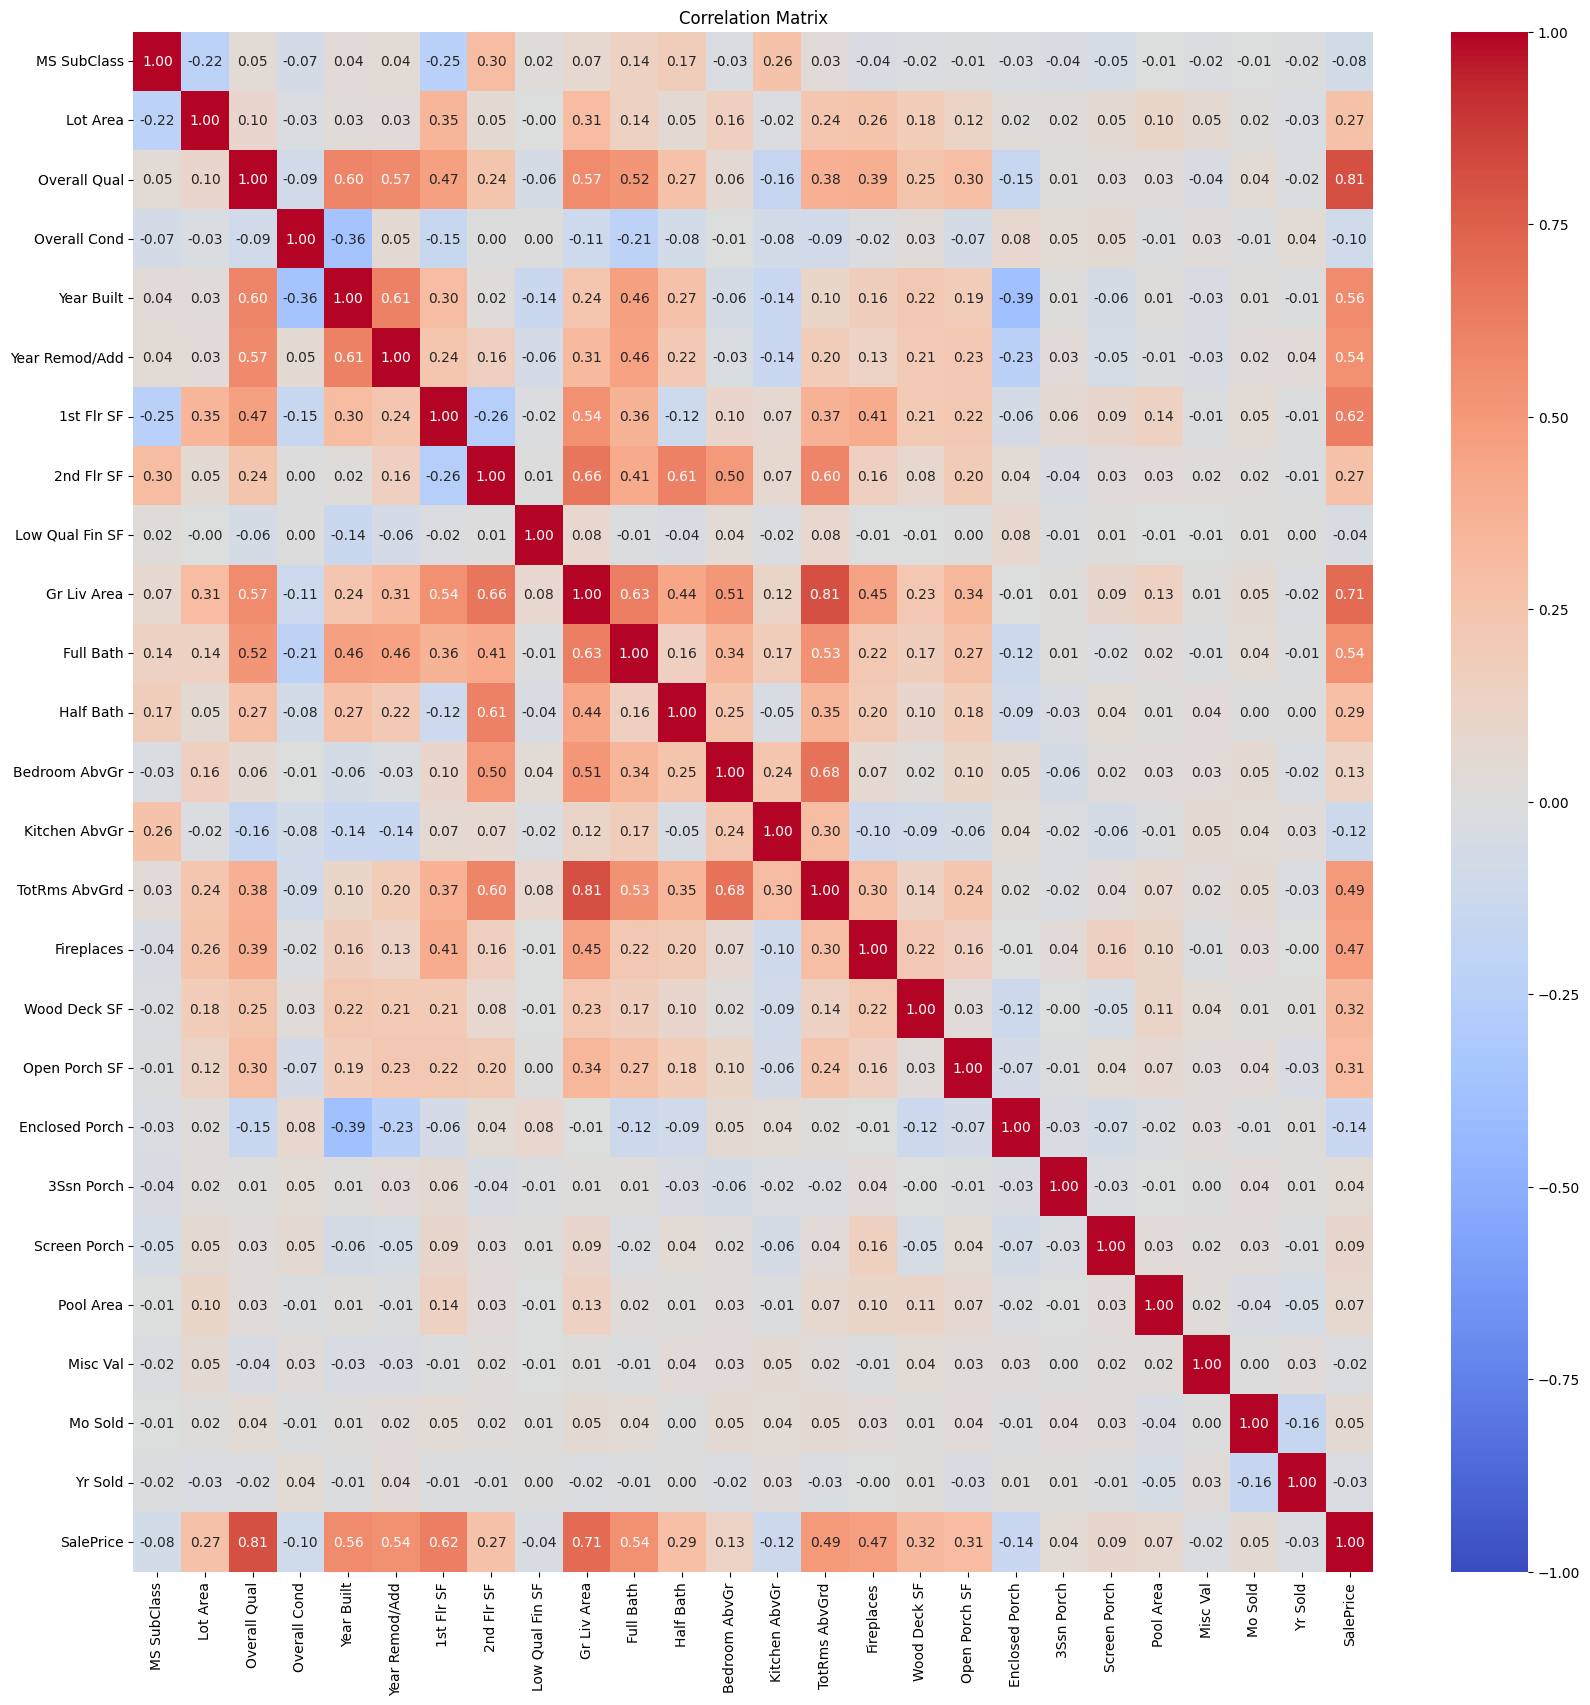

In [27]:
# Calcualte & display  correlation matrix, check if feature correlated with target
plt.figure(figsize=(20, 20))
sns.heatmap(house_df_target_floats.corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f',                 # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()

In [25]:
# Calculate a correlation matrix for features & features
features_df = house_df_target_floats.drop(columns=['SalePrice'])
features_corr = features_df.corr()

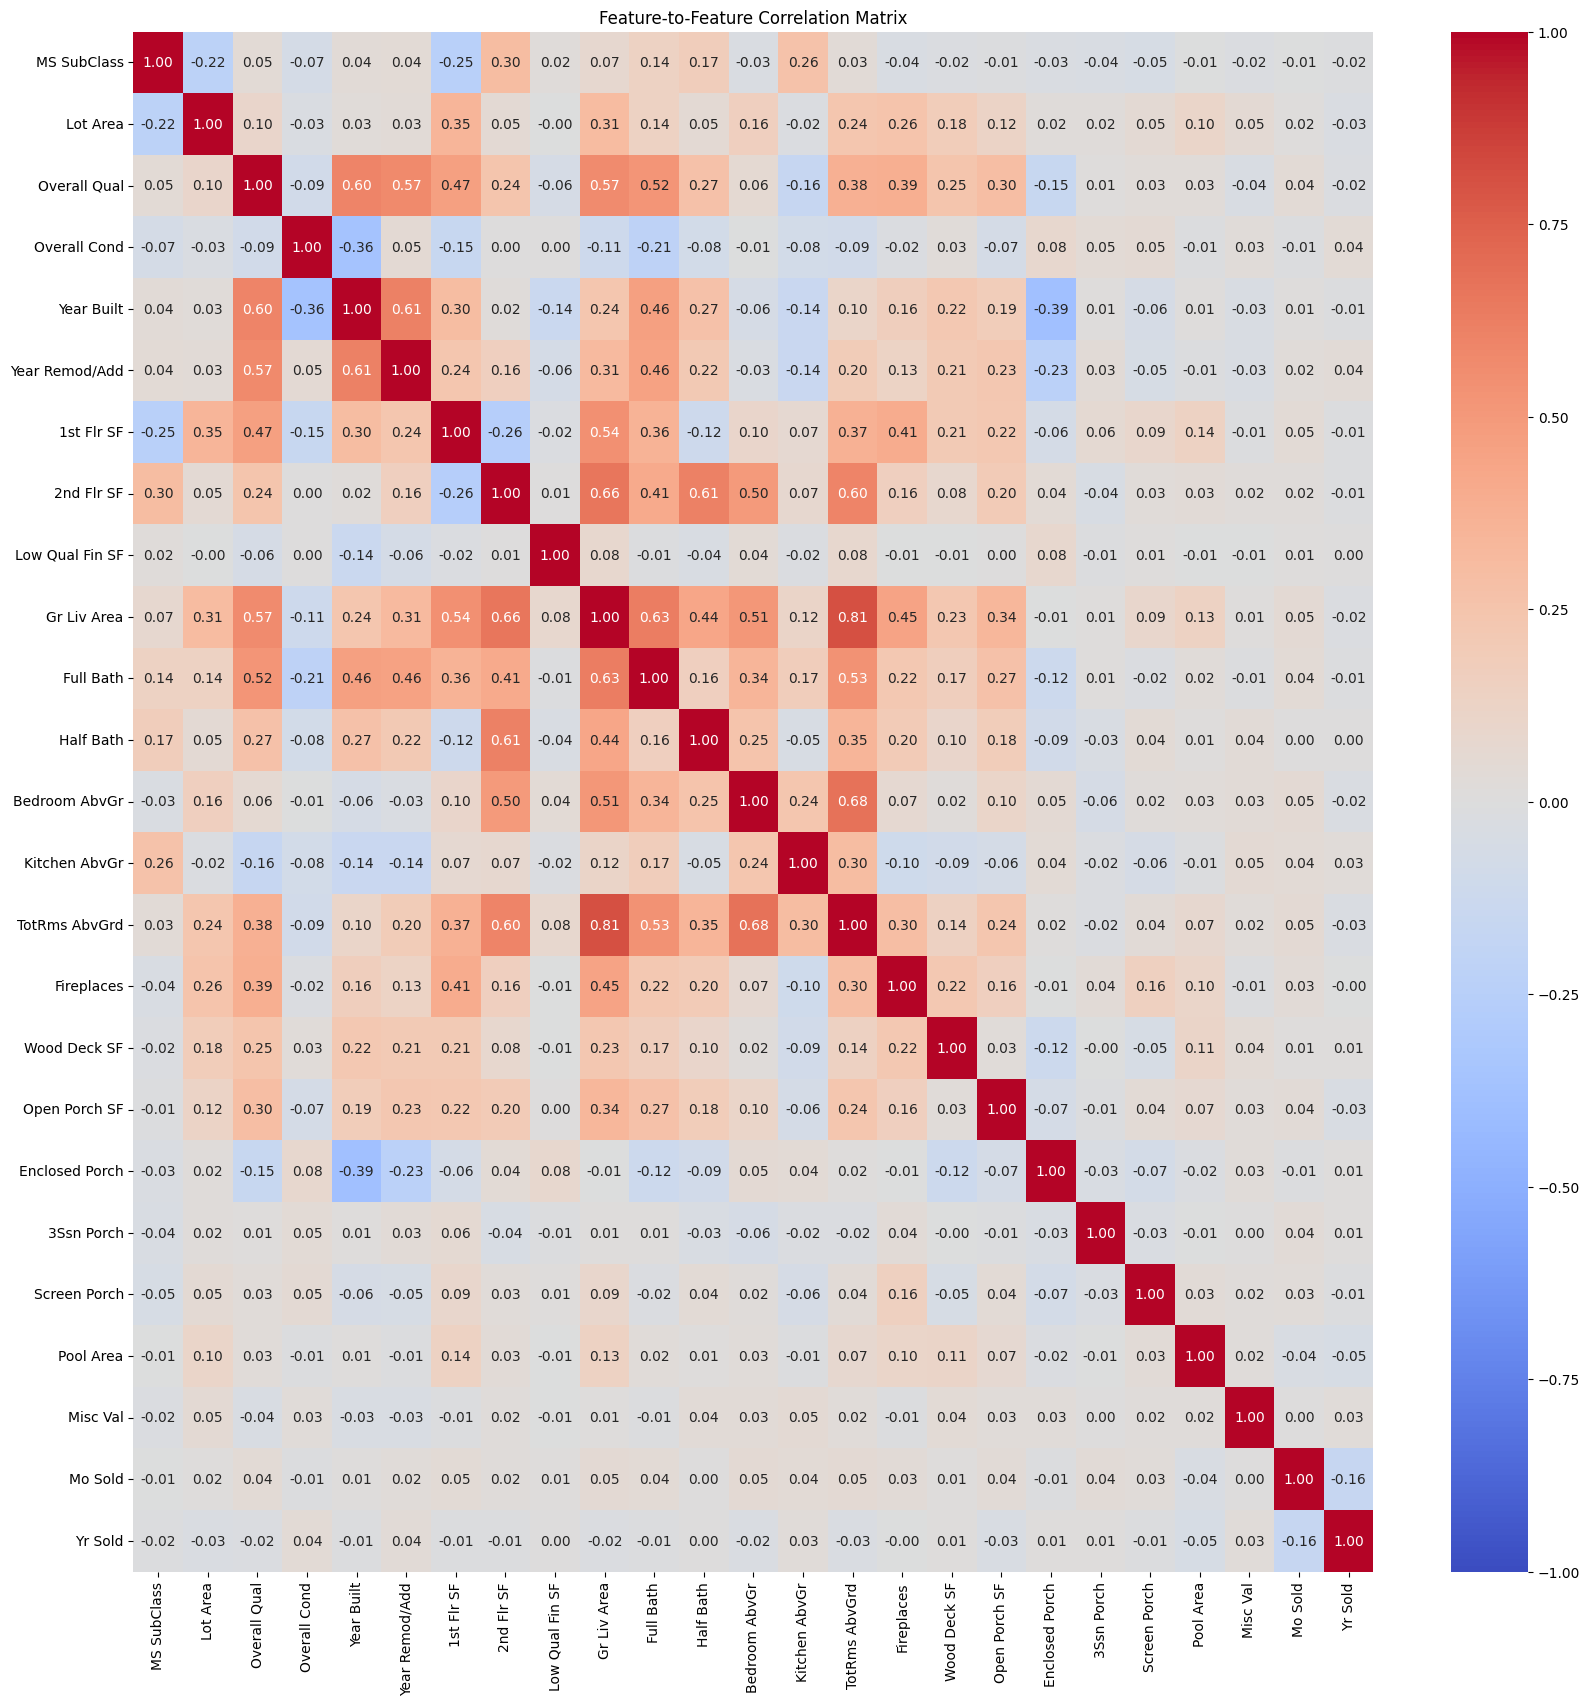

In [28]:
# Display the matrix, check if features are correlated with each other
plt.figure(figsize=(20, 20))      # bigger, since there are more columns
sns.heatmap(features_corr,
            annot=True,
            fmt='.2f',            # round numbers to 2 decimals so they fit
            cmap='coolwarm',
            center=0,
            vmin=-1, vmax=1)
plt.title('Feature-to-Feature Correlation Matrix')
plt.show()

## Processing



## Data Visualization/Communication of Results
